# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [3]:
import scipy.io

# Cargar el archivo .mat en un diccionario
datos = scipy.io.loadmat('data/ejer_1_data1.mat')

# Ver qué variables hay dentro del archivo
print(datos.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])


In [4]:
datos["X"]

array([[1.9643  , 4.5957  ],
       [2.2753  , 3.8589  ],
       [2.9781  , 4.5651  ],
       [2.932   , 3.5519  ],
       [3.5772  , 2.856   ],
       [4.015   , 3.1937  ],
       [3.3814  , 3.4291  ],
       [3.9113  , 4.1761  ],
       [2.7822  , 4.0431  ],
       [2.5518  , 4.6162  ],
       [3.3698  , 3.9101  ],
       [3.1048  , 3.0709  ],
       [1.9182  , 4.0534  ],
       [2.2638  , 4.3706  ],
       [2.6555  , 3.5008  ],
       [3.1855  , 4.2888  ],
       [3.6579  , 3.8692  ],
       [3.9113  , 3.4291  ],
       [3.6002  , 3.1221  ],
       [3.0357  , 3.3165  ],
       [1.5841  , 3.3575  ],
       [2.0103  , 3.2039  ],
       [1.9527  , 2.7843  ],
       [2.2753  , 2.7127  ],
       [2.3099  , 2.9584  ],
       [2.8283  , 2.6309  ],
       [3.0473  , 2.2931  ],
       [2.4827  , 2.0373  ],
       [2.5057  , 2.3853  ],
       [1.8721  , 2.0577  ],
       [2.0103  , 2.3546  ],
       [1.2269  , 2.3239  ],
       [1.8951  , 2.9174  ],
       [1.561   , 3.0709  ],
       [1.5495

In [5]:
datos["y"]

array([[1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1]], dtype=uint8)

In [6]:
datos["__globals__"]

[]

#### 3. Create a DataFrame with the features and target

In [7]:
df = pd.DataFrame(datos["X"], columns=["feature1", "feature2"])
df["target"] = datos["y"]
df

,feature1,feature2,target
0,1.964300,4.5957,1
1,2.275300,3.8589,1
2,2.978100,4.5651,1
3,2.932000,3.5519,1
4,3.577200,2.8560,1
5,4.015000,3.1937,1
6,3.381400,3.4291,1
7,3.911300,4.1761,1
8,2.782200,4.0431,1
9,2.551800,4.6162,1


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   feature1  51 non-null     float64
 1   feature2  51 non-null     float64
 2   target    51 non-null     uint8  
dtypes: float64(2), uint8(1)
memory usage: 999.0 bytes


In [9]:
df.describe()

,feature1,feature2,target
count,51.000000,51.000000,51.000000
mean,2.268780,3.132512,0.411765
std,0.928531,0.753256,0.497050
min,0.086405,1.617700,0.000000
25%,1.572550,2.636000,0.000000
50%,2.275300,3.070900,0.000000
75%,2.955050,3.531400,1.000000
max,4.015000,4.616200,1.000000


In [10]:
df["target"].value_counts()

target
0    30
1    21
Name: count, dtype: int64

#### 4. Plot a scatterplot with the data

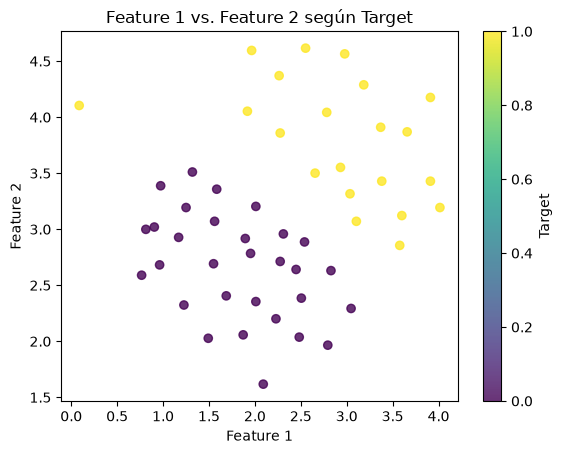

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
sc = ax.scatter(
    df["feature1"],
    df["feature2"],
    c=df["target"],
    cmap="viridis",
    alpha=0.8,
)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Feature 1 vs. Feature 2 según Target")
plt.colorbar(sc, ax=ax, label="Target")
plt.show()


Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [12]:
X = df[["feature1", "feature2"]]
y = df["target"]

In [13]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
lsvc = LinearSVC(C=1, loss='hinge', max_iter=10000, random_state=42)

scaled_lscv= Pipeline([
        ("scaler", scaler),
        ("linear_svc", lsvc),
    ])

#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [14]:
scaled_lscv.fit(X,y)

print("Score C=1 es de:", scaled_lscv.score(X, y))

Score C=1 es de: 0.9803921568627451


It appears that it mis-classified the outlier.

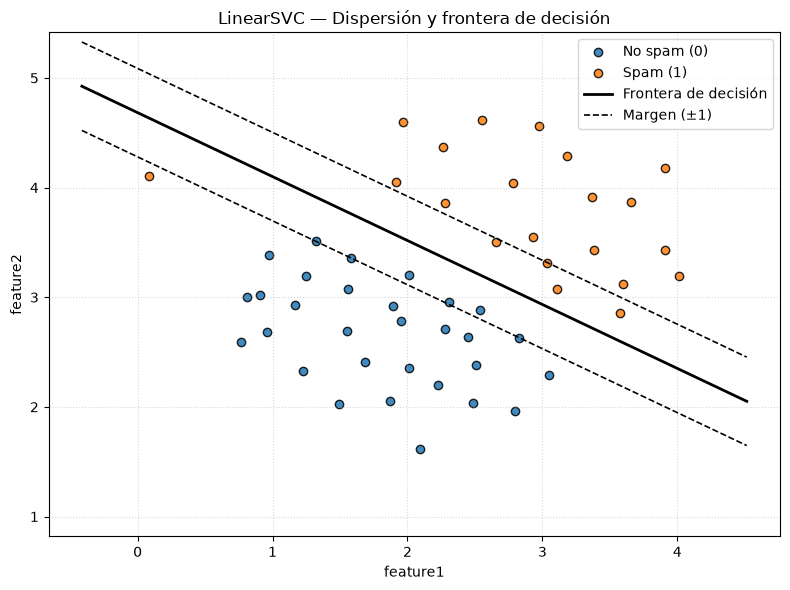

In [15]:
# 1. Extraer scaler y modelo del pipeline
scaler = scaled_lscv.named_steps["scaler"]
lsvc = scaled_lscv.named_steps["linear_svc"]

# Pesos y sesgo en la escala original de X (feature1, feature2)
w = lsvc.coef_[0] / scaler.scale_
b = lsvc.intercept_[0] - np.dot(lsvc.coef_[0], scaler.mean_ / scaler.scale_)

# 2. Scatter plot de los datos (ajusta los nombres de columnas si hace falta)
X_arr = X[["feature1", "feature2"]].to_numpy()
y_arr = np.asarray(y)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_arr[y_arr == 0, 0],
    X_arr[y_arr == 0, 1],
    label="No spam (0)",
    edgecolors="k",
    alpha=0.85,
)
plt.scatter(
    X_arr[y_arr == 1, 0],
    X_arr[y_arr == 1, 1],
    label="Spam (1)",
    edgecolors="k",
    alpha=0.85,
)

# 3. Recta de decisión: w[0]*x + w[1]*y + b = 0  =>  y = -(w[0]*x + b) / w[1]
ax = plt.gca()
x_vals = np.linspace(X_arr[:, 0].min() - 0.5, X_arr[:, 0].max() + 0.5, 200)

if not np.isclose(w[1], 0):
    y_decision = -(w[0] * x_vals + b) / w[1]
    # Márgenes: w[0]*x + w[1]*y + b = ±1  =>  y = -(w[0]*x + b ± 1) / w[1]
    y_margin_pos = -(w[0] * x_vals + b - 1) / w[1]
    y_margin_neg = -(w[0] * x_vals + b + 1) / w[1]

    plt.plot(x_vals, y_decision, "k-", linewidth=2, label="Frontera de decisión")
    plt.plot(x_vals, y_margin_pos, "k--", linewidth=1.2, label="Margen (±1)")
    plt.plot(x_vals, y_margin_neg, "k--", linewidth=1.2)

    # Limitar ejes a la región visible de los datos
    y_pad = (X_arr[:, 1].max() - X_arr[:, 1].min()) * 0.1 + 0.5
    plt.ylim(X_arr[:, 1].min() - y_pad, X_arr[:, 1].max() + y_pad)

plt.xlabel("feature1")
plt.ylabel("feature2")
plt.title("LinearSVC — Dispersión y frontera de decisión")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()



#### 7. Increase the value of C until you get a perfect classifier

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cs = list(range(1, 50))
scores = []

scaled_lsvc = Pipeline([
    ("scaler", StandardScaler()),
    ("linear_svc", LinearSVC(C=1, loss="hinge", max_iter=10000, random_state=42)),
])

for c in cs:
    scaled_lsvc.set_params(linear_svc__C=c)
    scaled_lsvc.fit(X, y)
    score = scaled_lsvc.score(X, y)
    scores.append(score)
    print(f"Score C={c} es de: {score:.3f}")

Score C=1 es de: 0.980
Score C=2 es de: 0.980
Score C=3 es de: 0.980
Score C=4 es de: 0.980
Score C=5 es de: 0.980
Score C=6 es de: 0.980
Score C=7 es de: 0.980
Score C=8 es de: 0.980
Score C=9 es de: 0.980
Score C=10 es de: 0.980
Score C=11 es de: 0.980
Score C=12 es de: 0.980
Score C=13 es de: 0.980
Score C=14 es de: 0.980
Score C=15 es de: 1.000
Score C=16 es de: 1.000
Score C=17 es de: 1.000
Score C=18 es de: 1.000
Score C=19 es de: 1.000
Score C=20 es de: 1.000
Score C=21 es de: 1.000
Score C=22 es de: 1.000
Score C=23 es de: 1.000
Score C=24 es de: 1.000
Score C=25 es de: 1.000
Score C=26 es de: 1.000
Score C=27 es de: 1.000
Score C=28 es de: 1.000
Score C=29 es de: 1.000
Score C=30 es de: 1.000
Score C=31 es de: 1.000
Score C=32 es de: 1.000
Score C=33 es de: 1.000
Score C=34 es de: 1.000
Score C=35 es de: 1.000
Score C=36 es de: 1.000
Score C=37 es de: 1.000
Score C=38 es de: 1.000
Score C=39 es de: 1.000
Score C=40 es de: 1.000
Score C=41 es de: 1.000
Score C=42 es de: 1.000
S

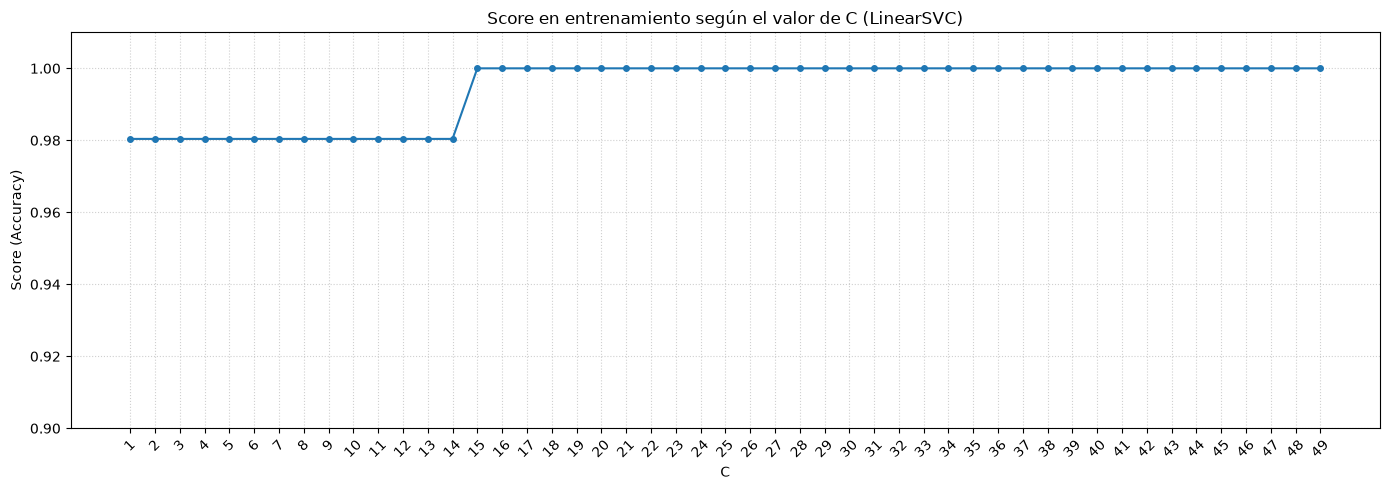

In [17]:
plt.figure(figsize=(14, 5))
plt.plot(cs, scores, marker="o", markersize=4, linewidth=1.5)

plt.title("Score en entrenamiento según el valor de C (LinearSVC)")
plt.xlabel("C")
plt.ylabel("Score (Accuracy)")
plt.xticks(cs, rotation=45)  # muestra todos los valores de C del 1 al 50
plt.ylim(0.9, 1.01)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

In [18]:
scaler = StandardScaler()
lsvc_2 = LinearSVC(C=15, loss='hinge', max_iter=10000, random_state=42)

scaled_lscv_2= Pipeline([
        ("scaler", scaler),
        ("linear_svc", lsvc_2)
        ])
 
scaled_lscv_2.fit(X,y)

print("Score C=15 es de:", scaled_lscv_2.score(X, y))   

Score C=15 es de: 1.0


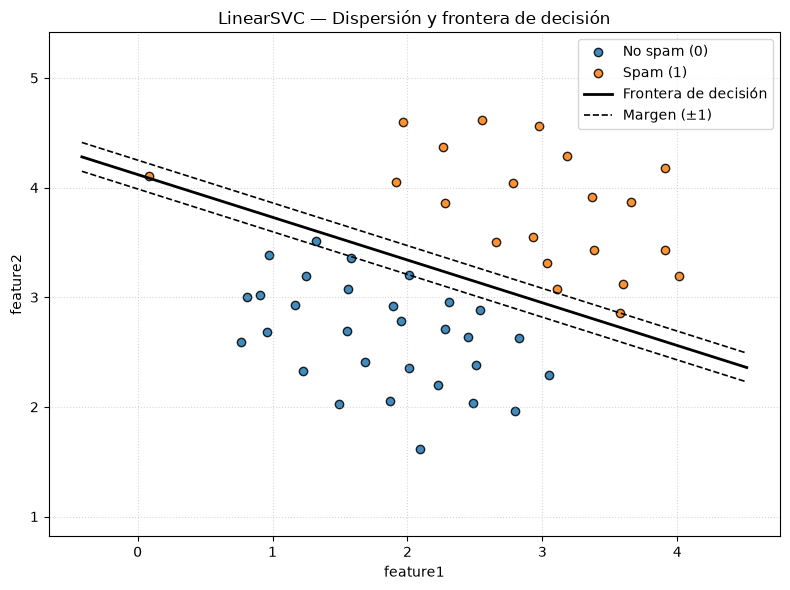

In [19]:
# 1. Extraer scaler y modelo del pipeline
scaler = scaled_lscv_2.named_steps["scaler"]
lsvc_2 = scaled_lscv_2.named_steps["linear_svc"]

# Pesos y sesgo en la escala original de X (feature1, feature2)
w = lsvc_2.coef_[0] / scaler.scale_
b = lsvc_2.intercept_[0] - np.dot(lsvc_2.coef_[0], scaler.mean_ / scaler.scale_)

# 2. Scatter plot de los datos (ajusta los nombres de columnas si hace falta)
X_arr = X[["feature1", "feature2"]].to_numpy()
y_arr = np.asarray(y)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_arr[y_arr == 0, 0],
    X_arr[y_arr == 0, 1],
    label="No spam (0)",
    edgecolors="k",
    alpha=0.85,
)
plt.scatter(
    X_arr[y_arr == 1, 0],
    X_arr[y_arr == 1, 1],
    label="Spam (1)",
    edgecolors="k",
    alpha=0.85,
)

# 3. Recta de decisión: w[0]*x + w[1]*y + b = 0  =>  y = -(w[0]*x + b) / w[1]
ax = plt.gca()
x_vals = np.linspace(X_arr[:, 0].min() - 0.5, X_arr[:, 0].max() + 0.5, 200)

if not np.isclose(w[1], 0):
    y_decision = -(w[0] * x_vals + b) / w[1]
    # Márgenes: w[0]*x + w[1]*y + b = ±1  =>  y = -(w[0]*x + b ± 1) / w[1]
    y_margin_pos = -(w[0] * x_vals + b - 1) / w[1]
    y_margin_neg = -(w[0] * x_vals + b + 1) / w[1]

    plt.plot(x_vals, y_decision, "k-", linewidth=2, label="Frontera de decisión")
    plt.plot(x_vals, y_margin_pos, "k--", linewidth=1.2, label="Margen (±1)")
    plt.plot(x_vals, y_margin_neg, "k--", linewidth=1.2)

    # Limitar ejes a la región visible de los datos
    y_pad = (X_arr[:, 1].max() - X_arr[:, 1].min()) * 0.1 + 0.5
    plt.ylim(X_arr[:, 1].min() - y_pad, X_arr[:, 1].max() + y_pad)

plt.xlabel("feature1")
plt.ylabel("feature2")
plt.title("LinearSVC — Dispersión y frontera de decisión")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

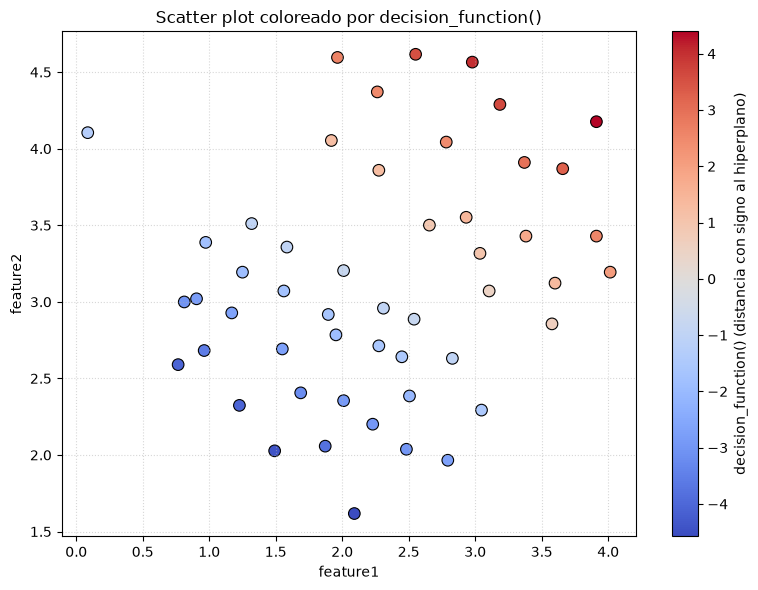

In [20]:
# 1. Obtener los valores de decision_function() del primer modelo
scores_df = scaled_lscv.decision_function(X)

# 2. Extraer las dos features (ajusta los nombres si no son "feature1" y "feature2")
x1 = X["feature1"]
x2 = X["feature2"]

# 3. Scatter plot coloreado según decision_function()
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    x1,
    x2,
    c=scores_df,
    cmap="coolwarm",  # azul/rojo para valores negativos/positivos
    edgecolors="k",
    linewidths=0.8,
    s=70,
)

# Barra de color para interpretar la escala
cbar = plt.colorbar(scatter)
cbar.set_label("decision_function() (distancia con signo al hiperplano)")

# Opcional: marcar la clase real con distintos marcadores para comparar
# (por ejemplo, círculos para 0 y triángulos para 1)
plt.xlabel("feature1")
plt.ylabel("feature2")
plt.title("Scatter plot coloreado por decision_function()")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

#### 9. Do the same with the second model

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

#### 1. Load the data `ejer_1_data2.mat`

In [39]:
datos2 = scipy.io.loadmat('data/ejer_1_data2.mat')
print(datos2.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])


#### 2. Create a DataFrame with the features and target

In [40]:
df2 = pd.DataFrame(datos2["X"], columns=["feature1", "feature2"])
df2["target"] = datos2["y"]
df2

,feature1,feature2,target
0,0.107143,0.603070,1
1,0.093318,0.649854,1
2,0.097926,0.705409,1
3,0.155530,0.784357,1
4,0.210829,0.866228,1
...,...,...,...
858,0.994240,0.516667,1
859,0.964286,0.472807,1
860,0.975806,0.439474,1
861,0.989631,0.425439,1


In [41]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   feature1  863 non-null    float64
 1   feature2  863 non-null    float64
 2   target    863 non-null    uint8  
dtypes: float64(2), uint8(1)
memory usage: 14.5 KB


In [42]:
df2.describe()

,feature1,feature2,target
count,863.000000,863.000000,863.000000
mean,0.503414,0.694304,0.556199
std,0.254967,0.158884,0.497120
min,0.044931,0.402632,0.000000
25%,0.292627,0.557018,0.000000
50%,0.512673,0.693713,1.000000
75%,0.699309,0.830409,1.000000
max,0.998848,0.988596,1.000000


In [43]:
df2["target"].value_counts()

target
1    480
0    383
Name: count, dtype: int64

#### 3. Plot a scatterplot with the data

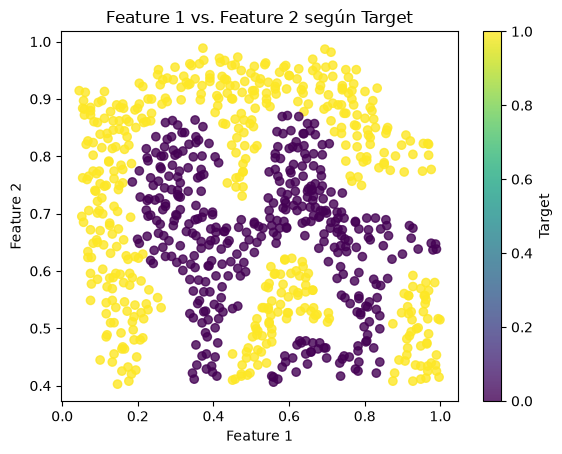

In [44]:
fig, ax = plt.subplots()
sc = ax.scatter(
    df2["feature1"],
    df2["feature2"],
    c=df2["target"],
    cmap="viridis",
    alpha=0.8,
)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Feature 1 vs. Feature 2 según Target")
plt.colorbar(sc, ax=ax, label="Target")
plt.show()

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [45]:
from sklearn.model_selection import train_test_split

X = df2[["feature1", "feature2"]]
y = df2["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [46]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

svc_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", CalibratedClassifierCV(SVC(C=100, gamma=10), ensemble=False)) # con probability=True sale warning y hay que usar ahora CalibratedClassifierCV(SVC(), ensemble=False)
    ])

#### 5. Fit the classifier and get the score

In [47]:
svc_clf.fit(X_train, y_train) 

print("El score en train de SVC con los hiperparámetros pedidos ha sido de", svc_clf.score(X_train, y_train))

El score en train de SVC con los hiperparámetros pedidos ha sido de 1.0


In [48]:
print("El score en test de SVC con los hiperparámetros pedidos ha sido de", svc_clf.score(X_test, y_test))

El score en test de SVC con los hiperparámetros pedidos ha sido de 0.9884393063583815


El score es casi perfecto en ambos, así que genial! No hay overfit! 

El modelo entrenado consigue diferenciar bien las dos clases (spam/no spam)

In [49]:
predictions_test = svc_clf.predict(X_test)
predictions_train = svc_clf.predict(X_train)

from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, classification_report

print(f"Accuracy train: {accuracy_score(y_train, predictions_train):.3f}")
print(f"Accuracy test:  {accuracy_score(y_test, predictions_test):.3f}")
print(f"Precision test: {precision_score(y_test, predictions_test, zero_division=0):.3f}")
print(f"Recall test:    {recall_score(y_test, predictions_test, zero_division=0):.3f}")
print(f"F1 test:        {f1_score(y_test, predictions_test, zero_division=0):.3f}")

print("\nMatriz de confusión (test):")
print(confusion_matrix(y_test, predictions_test))

print("\nReporte detallado:")
print(classification_report(y_test, predictions_test, zero_division=0))

Accuracy train: 1.000
Accuracy test:  0.988
Precision test: 1.000
Recall test:    0.977
F1 test:        0.989

Matriz de confusión (test):
[[85  0]
 [ 2 86]]

Reporte detallado:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        85
           1       1.00      0.98      0.99        88

    accuracy                           0.99       173
   macro avg       0.99      0.99      0.99       173
weighted avg       0.99      0.99      0.99       173



Divino, el modelo tiene dos False Negative, es decir, sólo se le ha escapado un 2% como spam, pero acierta el 98% (recall 0.98 en clase 1).

#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

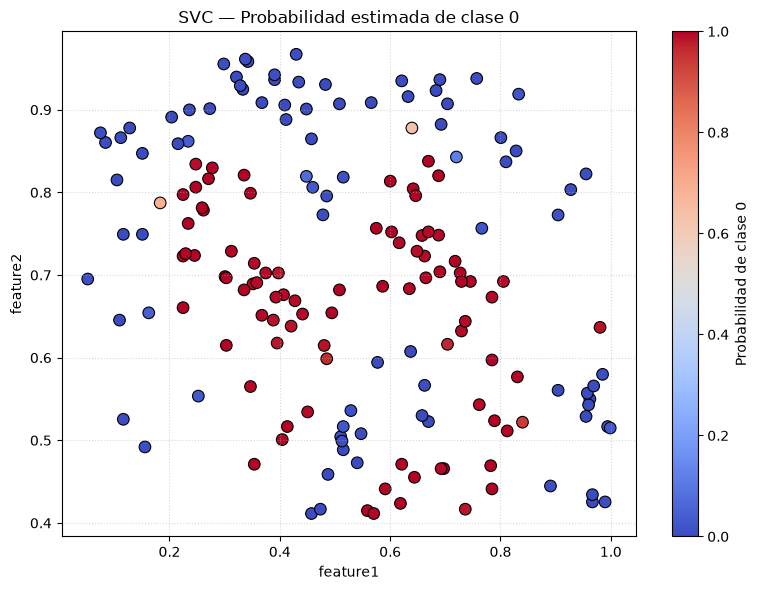

In [50]:
# Probabilidad de predecir la clase 0 (columna 0 de predict_proba)
prob_0 = svc_clf.predict_proba(X_test)[:, 0] # X_test para usarlo para predicción


plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_test["feature1"],
    X_test["feature2"],
    c=prob_0,
    cmap="coolwarm",  
    vmin=0.0,
    vmax=1.0,
    edgecolors="k",
    linewidths=0.8,
    s=70,
)

cbar = plt.colorbar(scatter)
cbar.set_label("Probabilidad de clase 0")

plt.xlabel("feature1")
plt.ylabel("feature2")
plt.title("SVC — Probabilidad estimada de clase 0")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

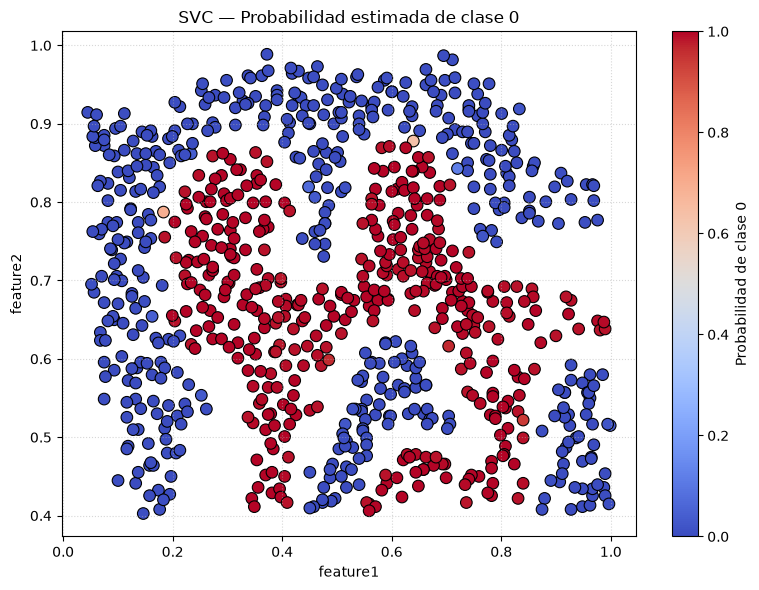

In [51]:
# Probabilidad de predecir la clase 0 (columna 0 de predict_proba)
prob_0 = svc_clf.predict_proba(X)[:, 0] # X_test para usarlo para predicción


plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X["feature1"],
    X["feature2"],
    c=prob_0,
    cmap="coolwarm",  
    vmin=0.0,
    vmax=1.0,
    edgecolors="k",
    linewidths=0.8,
    s=70,
)

cbar = plt.colorbar(scatter)
cbar.set_label("Probabilidad de clase 0")

plt.xlabel("feature1")
plt.ylabel("feature2")
plt.title("SVC — Probabilidad estimada de clase 0")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()